# Zernike 像差拟合：Python/JAX 学习版

基于官方 zernike_fitting.ipynb。原版不动。先读 README_zh.md 中的官方复现和错误记录。这里使用官方系数的 0.2 倍、无噪声、256×256；与完整官方复现实验分开。下方代码单元已由 Python 顺序执行并保存输出。

## 1. 参数与导入

全部长度为 µm；SHAPE 是实际输出像素数，IMAGE_DX 是像面采样。jnp 用于可微计算，np 用于保存/绘图。ANSI 1..10 不含不可观测的全局相位 piston。

In [1]:
"""Zernike 像差拟合：只优化一个长度为 10 的数组。详见 README_zh.md。"""
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("MPLBACKEND", "Agg")
from pathlib import Path
import argparse
import json
import csv
import jax
import jax.numpy as jnp
import numpy as np
import optax
import matplotlib.pyplot as plt
import chromatix.functional as cx
from chromatix.utils import zernike_aberrations

# 全部长度为 µm；此处采用与官方相同的标量、近轴、单波长模型。
WAVELENGTH = 0.532           # 真空波长 [µm]
F = 100.0                   # 焦距 [µm]；前后焦平面间傅里叶变换
N_MEDIUM = 1.33             # 折射率 [无量纲]
NA = 0.8                    # 数值孔径 [无量纲]
SHAPE = (256, 256)          # 教学版直接输出此尺寸，不做隐藏过采样
IMAGE_DX = 0.125            # PSF 平面采样 [µm/pixel]
PUPIL_DX = F * WAVELENGTH / (N_MEDIUM * SHAPE[0] * IMAGE_DX)
INDICES = tuple(range(1, 11))  # ANSI 1..10；没有 piston (ANSI 0)
K0 = 2 * np.pi / WAVELENGTH # 真空波数 [rad/µm]



## 2. PSF 正向模型

c `(10,)` 为 OPD 系数 [µm]；basis `(10,256,256)` 为 rad/µm；phase `(256,256)` 为 rad；PSF `(256,256)` 为模拟强度。vmap 批量计算基函数，einsum 沿模式维求和。仅固定 basis，梯度仍通过相位和 FFT 传回系数。

In [2]:
def make_forward():
    # 固定物理参数与基函数只算一次；coefficients 才是待估参数。
    pupil = cx.objective_point_source(SHAPE, PUPIL_DX, WAVELENGTH,
                                     0.0, F, N_MEDIUM, NA, power=1e3)
    # basis[k,y,x] [rad/µm]：第 k 个 OPD 系数为 1 µm 时的相位。
    # vmap 是对 10 个单位系数向量批量调用，与 MATLAB 循环计算各基函数等价。
    basis = jax.vmap(lambda c: zernike_aberrations(
        SHAPE, PUPIL_DX, WAVELENGTH, N_MEDIUM, F, NA,
        INDICES, c, normalize=False))(jnp.eye(10))  # (10,256,256)

    def forward(coefficients):  # coefficients: (10,), OPD [µm]
        phase = jnp.einsum("k,kyx->yx", coefficients, basis)  # (256,256), rad
        field = cx.phase_change(pupil, phase)
        field = cx.ff_lens(field, F, N_MEDIUM)
        return field.intensity.squeeze()  # (256,256), 模拟强度，非 SI 标定
    return forward



## 3. Loss、自动求导与正确的优化循环

Loss 是标量 `()`，gradient 为 `(10,)` [µm⁻¹]。value_and_grad 同时给出 Loss 和梯度；jit 编译更新步骤。Adam 的 state 必须返回并传入下一次迭代。保留中心差分核对，以独立检查梯度。单张 PSF 相位反演非凸；此小像差例的成功不代表一般唯一性。

In [3]:
def fit(steps=2000, learning_rate=0.001):
    forward = make_forward()
    truth = 0.2 * jnp.array([2., 5., 3., 0., 1., 0., 1., 0., 1., 0.]) / K0
    # 教学版真值为官方的 0.2 倍，并去掉 Poisson 噪声；完整官方对照另见复现脚本。
    target = forward(truth)           # (256,256)
    coefficients = jnp.zeros(10)      # (10,), µm；从无像差开始
    initial = forward(coefficients)   # (256,256)

    def loss_fn(c):
        prediction = forward(c)      # (256,256)
        return jnp.mean((prediction-target)**2) / jnp.mean(target**2)  # (), 无量纲

    optimizer = optax.adam(learning_rate)
    state = optimizer.init(coefficients)  # PyTree：步数、(10,) 一阶和二阶矩

    @jax.jit
    def step(c, state):
        # 自动求导：一个标量 Loss -> 对全部 10 个系数的梯度。
        loss, gradient = jax.value_and_grad(loss_fn)(c)  # (), (10,)
        updates, new_state = optimizer.update(gradient, state, c)
        new_c = optax.apply_updates(c, updates)         # (10,), µm
        return new_c, new_state, loss  # 必须把状态传回下一次迭代！

    # 用中心差分独立核对自动梯度；在非零点检查，避免对称点出现零梯度。
    probe = truth * 0.37
    grad = np.asarray(jax.grad(loss_fn)(probe))
    delta = 1e-4  # µm，float32 下避免差分消去过强
    fd = np.array([float((loss_fn(probe+jnp.eye(10)[k]*delta)
                         -loss_fn(probe-jnp.eye(10)[k]*delta))/(2*delta)) for k in range(10)])
    grad_rel_error = float(np.linalg.norm(grad-fd)/np.linalg.norm(fd))
    assert grad_rel_error < 0.02, (grad_rel_error, grad, fd)

    history = []
    for iteration in range(steps):
        coefficients, state, loss = step(coefficients, state)
        history.append(float(loss))  # 这里是更新前的 Loss
        if iteration % 200 == 0:
            print(f"step={iteration}, loss={history[-1]:.7g}", flush=True)
    history.append(float(loss_fn(coefficients)))  # 最终更新后的 Loss
    optimized = forward(coefficients)
    arrays = dict(initial=np.asarray(initial), target=np.asarray(target),
        optimized=np.asarray(optimized), truth=np.asarray(truth),
        fitted=np.asarray(coefficients), history=np.asarray(history))
    assert all(np.isfinite(a).all() for a in arrays.values())
    assert int(state[0].count) == steps
    assert history[-1] < history[0] * 0.01
    return arrays, dict(initial_loss=history[0], final_loss=history[-1],
        coefficient_rmse_um=float(np.sqrt(np.mean((arrays['fitted']-arrays['truth'])**2))),
        adam_count=int(state[0].count), gradient_relative_error=grad_rel_error,
        shape=list(SHAPE), pupil_dx_um=PUPIL_DX, image_dx_um=IMAGE_DX,
        jax=jax.__version__, devices=[str(d) for d in jax.devices()],
        steps=steps, learning_rate=learning_rate, noisy_target=False, truth_scale_vs_official=0.2)



## 4. 执行拟合并检查结果

2000 步，学习率 0.001。history `(2001,)` 包含初始和最终更新后的 Loss。下面打印来自实际运行的指标。

In [4]:
arrays, summary = fit()
print(json.dumps(summary, indent=2))


step=0, loss=0.3339401
step=200, loss=0.001626394
step=400, loss=4.03784e-05
step=600, loss=1.435154e-07
step=800, loss=9.926657e-11
step=1000, loss=7.769994e-14
step=1200, loss=6.675282e-14
step=1400, loss=4.608008e-14
step=1600, loss=3.029246e-14
step=1800, loss=2.712735e-14
{
  "initial_loss": 0.3339400589466095,
  "final_loss": 2.8011203382846683e-14,
  "coefficient_rmse_um": 2.4406045184832692e-08,
  "adam_count": 2000,
  "gradient_relative_error": 0.00011106825157402935,
  "shape": [
    256,
    256
  ],
  "pupil_dx_um": 1.25,
  "image_dx_um": 0.125,
  "jax": "0.12.0.1",
  "devices": [
    "cpu:0"
  ],
  "steps": 2000,
  "learning_rate": 0.001,
  "noisy_target": false,
  "truth_scale_vs_official": 0.2
}


## 5. 保存初始/目标/优化 PSF、Loss 和系数结果

三个 PSF 使用相同色标；csv 中系数单位为 µm OPD，额外提供 rad 相位系数。npz 保存完整数值。像面图横纵坐标为 µm。

In [5]:
def save_results(arrays, summary, out):
    out.mkdir(exist_ok=True, parents=True)
    np.savez_compressed(out/'learning_arrays.npz', **arrays)
    (out/'learning_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
    with (out/'coefficients.csv').open('w',newline='',encoding='utf-8') as f:
        writer=csv.writer(f)
        writer.writerow(['ANSI','truth_OPD_um','fitted_OPD_um','error_OPD_um','truth_phase_rad','fitted_phase_rad'])
        for k,t,c in zip(INDICES,arrays['truth'],arrays['fitted']):
            writer.writerow([k,float(t),float(c),float(c-t),float(t*K0),float(c*K0)])
    with (out/'loss.csv').open('w',newline='',encoding='utf-8') as f:
        writer=csv.writer(f); writer.writerow(['updates_completed','normalized_MSE'])
        writer.writerows(enumerate(arrays['history']))
    # 三幅 PSF 相同色标、相同裁剪范围；避免各自自动拉伸掩盖拟合误差。
    fig,axs=plt.subplots(1,3,figsize=(12,4),layout='constrained')
    radius=16; center=SHAPE[0]//2
    extent=np.array([-radius-.5,radius-.5,-radius-.5,radius-.5])*IMAGE_DX
    vmax=max(arrays[name].max() for name in ('initial','target','optimized'))
    for ax,name in zip(axs,('initial','target','optimized')):
        image=arrays[name][center-radius:center+radius,center-radius:center+radius]
        im=ax.imshow(image,cmap='afmhot',vmin=0,vmax=vmax,extent=extent,origin='lower')
        ax.set(title=name,xlabel='x (um)',ylabel='y (um)')
    fig.colorbar(im,ax=axs,label='Simulation intensity (common scale)',shrink=.7)
    fig.savefig(out/'psfs.png',dpi=160); plt.close(fig)
    fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    axs[0].semilogy(arrays['history']); axs[0].set(xlabel='Updates completed',ylabel='Normalized MSE',title='Loss')
    axs[1].plot(INDICES,arrays['truth'],'o-',label='truth')
    axs[1].plot(INDICES,arrays['fitted'],'x--',label='fitted')
    axs[1].set(xlabel='ANSI index',ylabel='OPD coefficient (um)',title='Zernike coefficients'); axs[1].legend()
    fig.savefig(out/'fit.png',dpi=160); plt.close(fig)



Saved: E:\Optical beam design_codex project\chromatix\learning\zernike\results


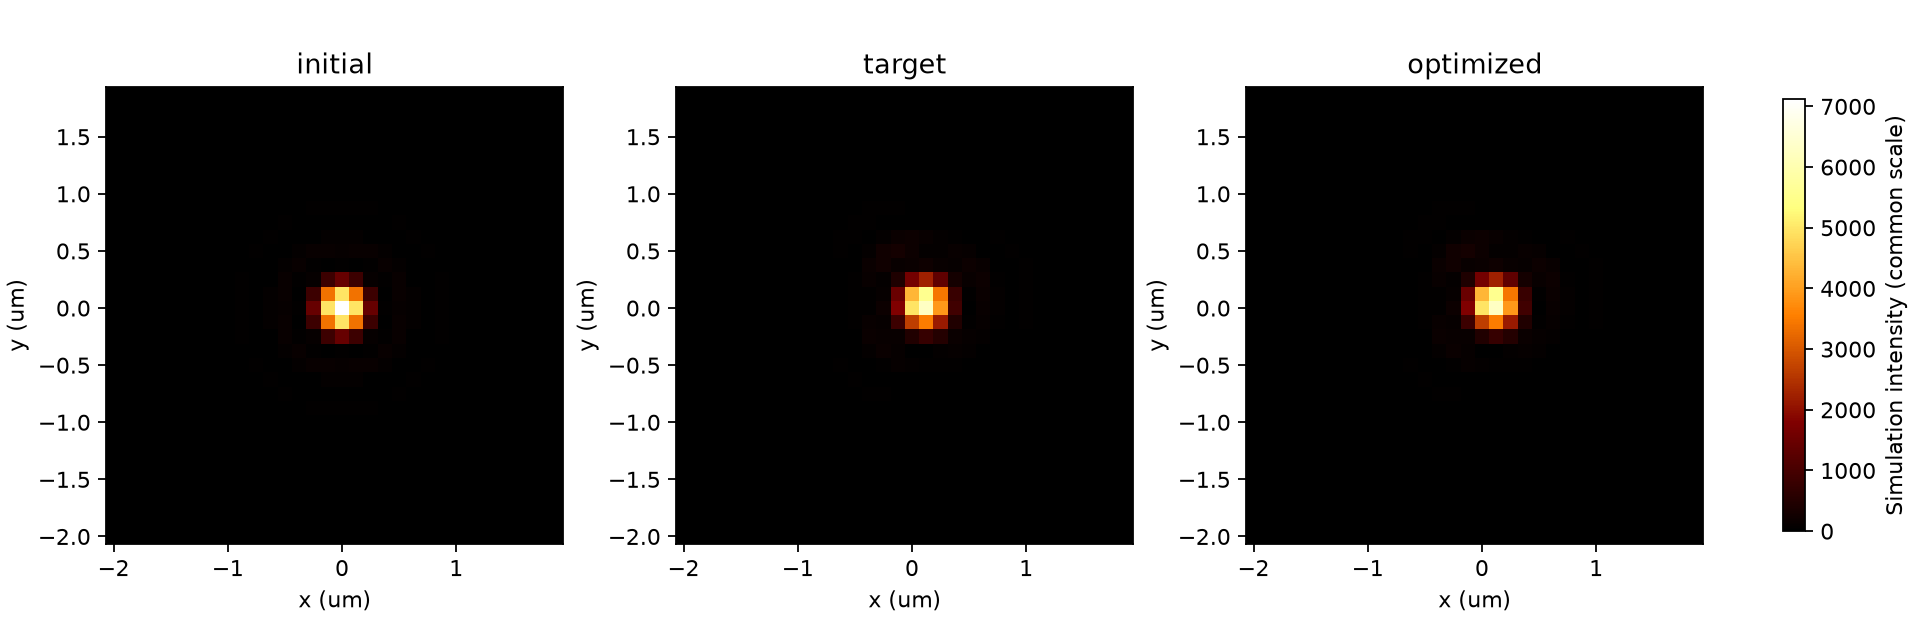

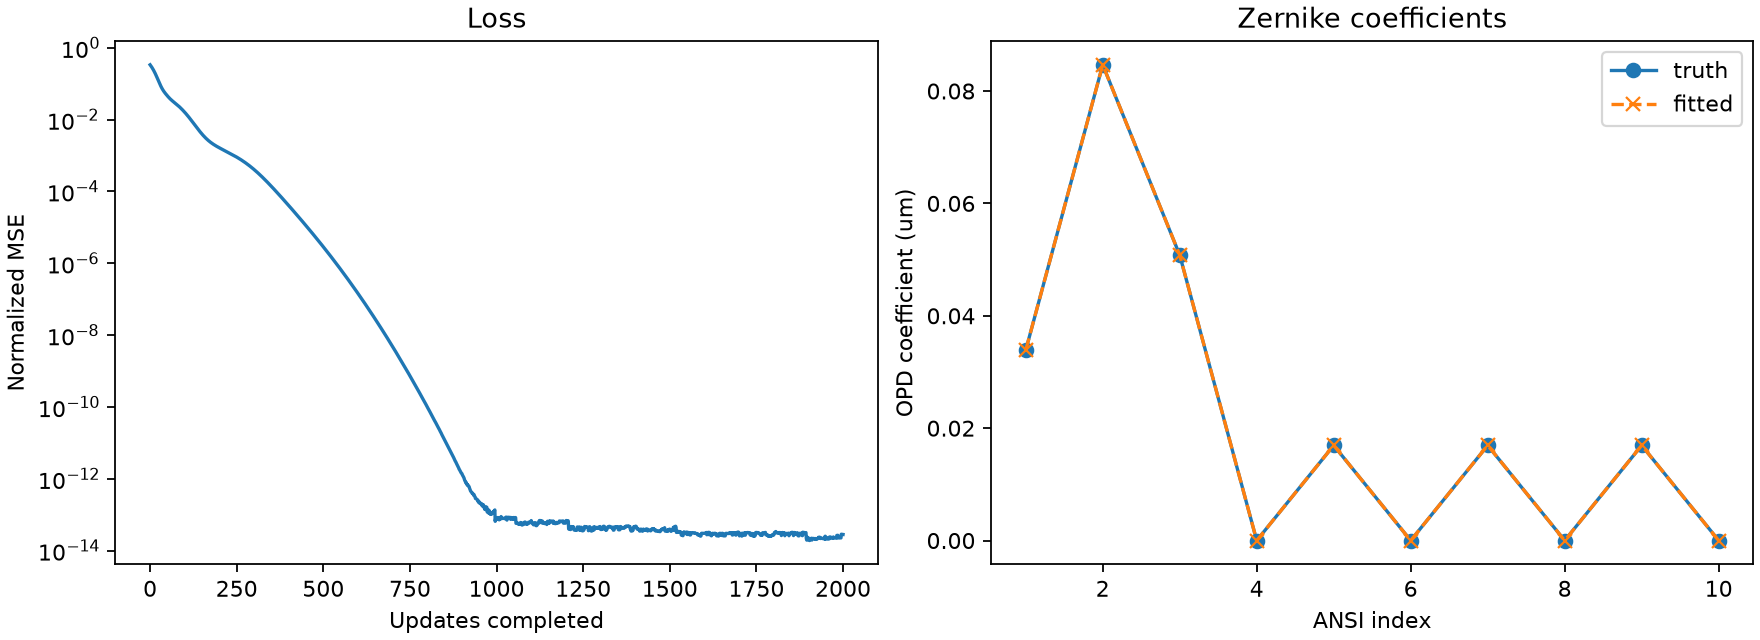

In [6]:
out = Path('learning/zernike/results') if Path('learning/zernike').exists() else Path('results')
save_results(arrays, summary, out)
print('Saved:', out.resolve())


## 6. 完整官方复现的结论

原版 1000 步 Loss≈0.0017407，外层 Adam count=0；仅修正状态后 Loss≈0.0884967，count=1000。相同学习率和迭代数下正确 Adam 没有更好，必须重新调参或考虑多初值/phase diversity。静态 ANSI 数组在当前 JAX 触发缓存元数据比较错误，独立副本以 tuple 解决。详细错误栈、物理公式、数组 shape 和 MATLAB 对照见 README_zh.md。